<div style="background: linear-gradient(90deg, #1e3a5f, #2b6cb0); padding: 28px 24px; border-radius: 10px; color: white; text-align: center; max-width: 900px; margin: 0 auto;">
  <h1 style="margin: 0; color: white;">✈️ Airline Passenger Satisfaction</h1>
  <p style="margin: 6px 0 0 0; font-size: 16px; color: #dbeafe;">
    Notebook 1 · Exploratory Data Analysis
  </p>
</div>

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
pd.set_option ("display.max_columns",None)

In [13]:
DATA_DIR = Path("../data/raw")

In [17]:
def load_data():
    train = pd.read_csv(DATA_DIR/"train.csv")
    test = pd.read_csv(DATA_DIR/"test.csv")
    return train,test
train,test = load_data()

In [18]:
train.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

In [16]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [19]:
train.shape

(699635, 23)

In [24]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372130,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


In [25]:
train.isna().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [26]:
train["satisfaction"].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

## Data overview

- **Size:** 699,635 rows × 23 columns in `train`.
- **Identifier:** `id` is only a row number, so it is not a feature.
- **Target:** `satisfaction`, with two classes:
  - `False` (not satisfied): 389,296 rows (55.6%)
  - `True` (satisfied): 310,339 rows (44.4%)
  - The classes are fairly balanced, so accuracy is meaningful here (unlike fraud, where only 1.7% of rows were positive).
- **Features (21):**
  - 13 service ratings on a 0–5 scale (wifi, food and drink, seat comfort, cleanliness, ...)
  - 4 numeric: `Age`, `Flight Distance`, `Departure Delay in Minutes`, `Arrival Delay in Minutes`
  - 4 categorical: `Gender`, `Customer Type`, `Type of Travel`, `Class`
- **Missing values:** only `Arrival Delay in Minutes` has any, 292 rows (0.04%). Everything else is complete.
- **Delays are very skewed:** the median is 0 minutes, but the maximum is about 490. Most flights are on time, and a few are extremely late.
- **Ratings of 0:** many service ratings have a minimum of 0, while `Baggage handling` starts at 1. A 0 might mean "not applicable" rather than "very bad", so I need to check this before treating it as a score.

### Things to check next
1. What does a rating of 0 mean, and how does satisfaction change for those passengers?
2. Do the two delay columns carry the same information? (They look strongly related.)
3. Which service ratings separate satisfied from unsatisfied passengers the most?

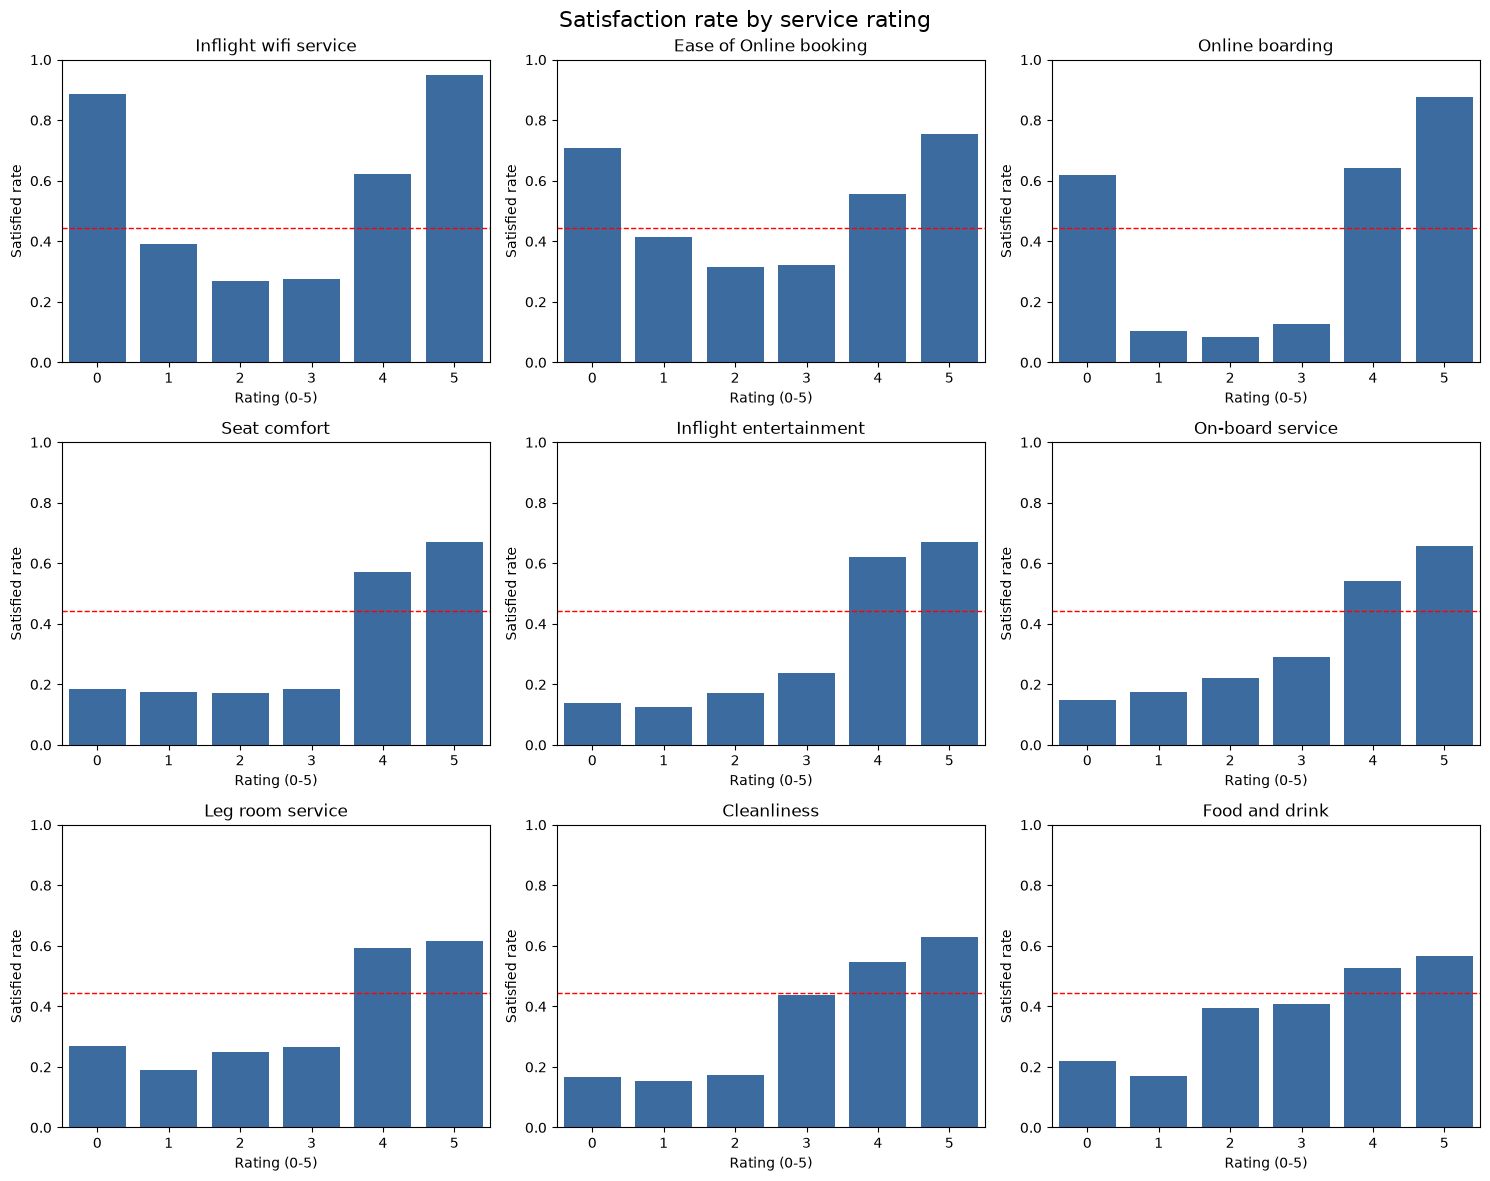

In [27]:
rating_cols = [
    "Inflight wifi service", "Ease of Online booking", "Online boarding",
    "Seat comfort", "Inflight entertainment", "On-board service",
    "Leg room service", "Cleanliness", "Food and drink",
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, rating_cols):
    rate = train.groupby(col)["satisfaction"].mean()
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#2b6cb0")
    ax.axhline(train["satisfaction"].mean(), color="red", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Rating (0-5)")
    ax.set_ylabel("Satisfied rate")
    ax.set_ylim(0, 1)

fig.suptitle("Satisfaction rate by service rating", fontsize=16)
plt.tight_layout()
plt.show()

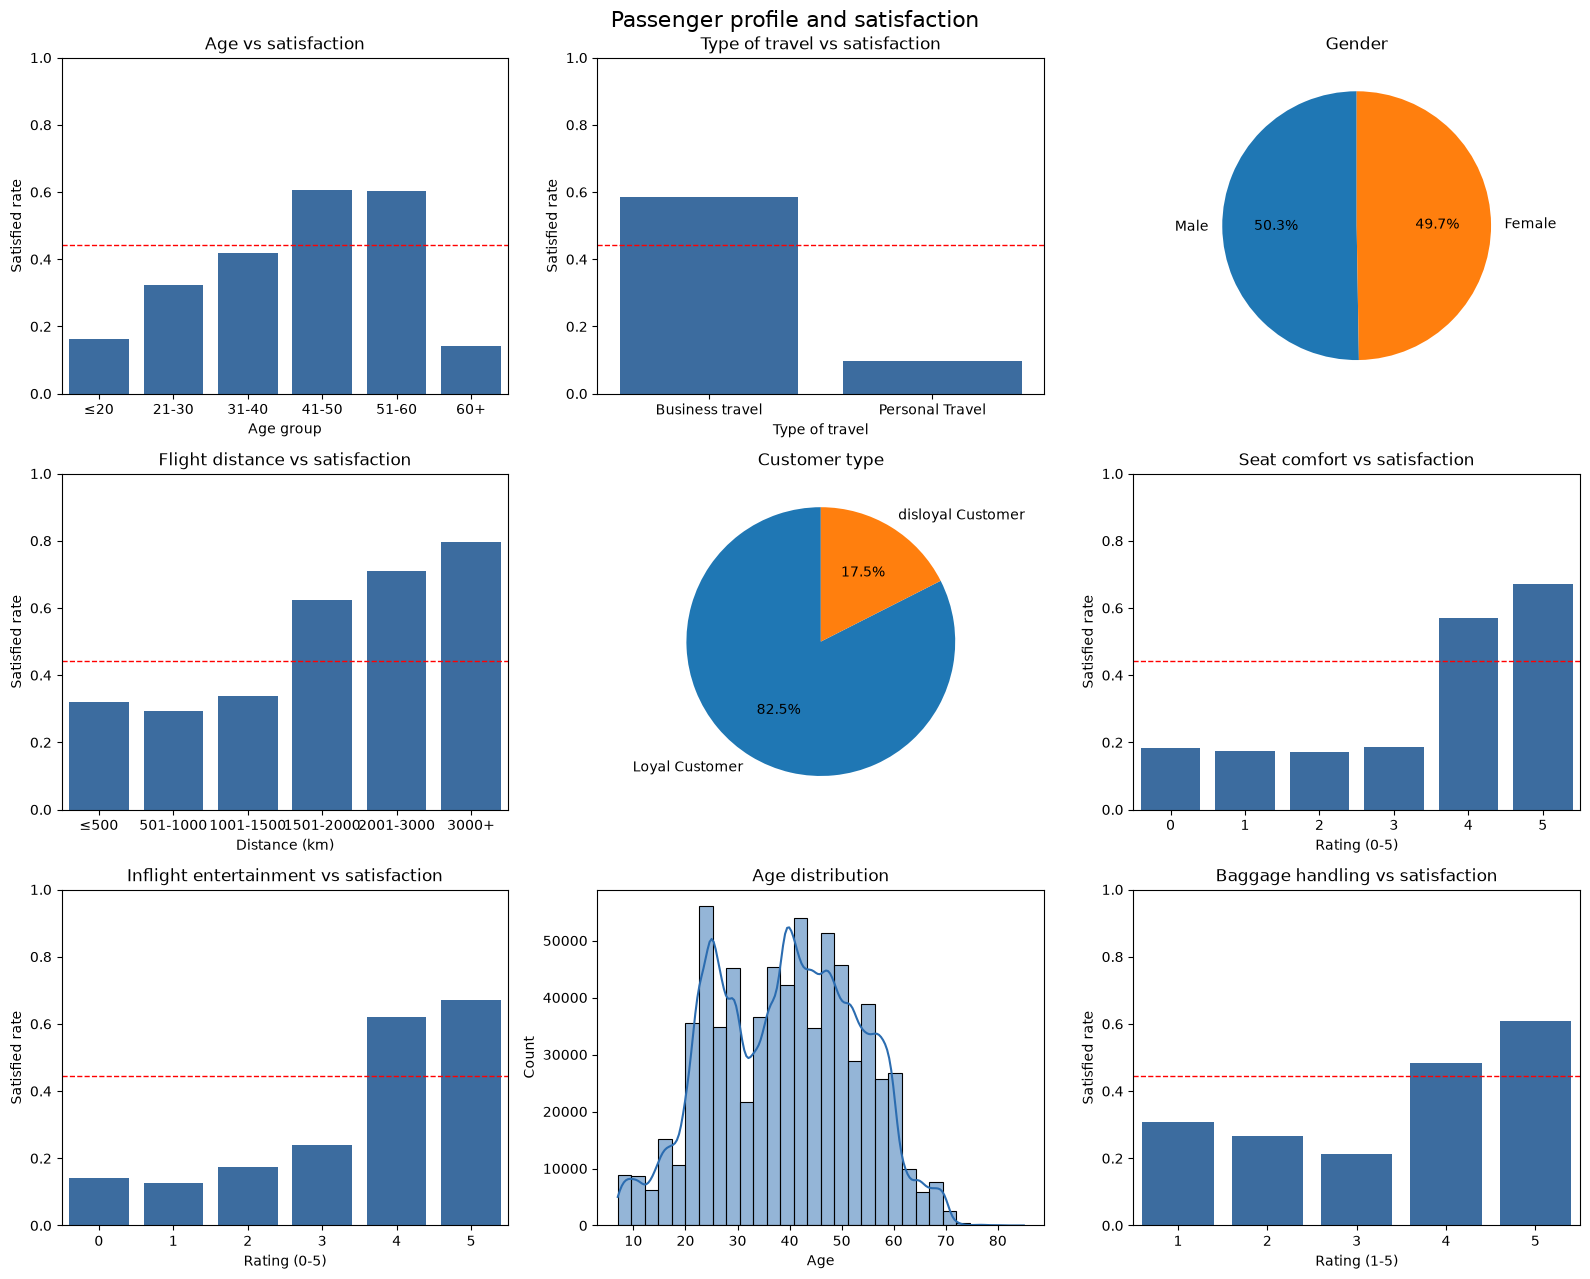

In [28]:
overall = train["satisfaction"].mean()

def rate_plot(ax, groups, title, xlabel):
    """Bar chart of the satisfied rate for each group."""
    rate = train.groupby(groups, observed=True)["satisfaction"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#2b6cb0")
    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Satisfied rate")
    ax.set_ylim(0, 1)

age_groups = pd.cut(train["Age"], [0, 20, 30, 40, 50, 60, 100],
                    labels=["≤20", "21-30", "31-40", "41-50", "51-60", "60+"])
dist_groups = pd.cut(train["Flight Distance"], [0, 500, 1000, 1500, 2000, 3000, 5000],
                     labels=["≤500", "501-1000", "1001-1500", "1501-2000", "2001-3000", "3000+"])

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

rate_plot(axes[0], age_groups, "Age vs satisfaction", "Age group")
rate_plot(axes[1], train["Type of Travel"], "Type of travel vs satisfaction", "Type of travel")

train["Gender"].value_counts().plot.pie(ax=axes[2], autopct="%1.1f%%", startangle=90)
axes[2].set_title("Gender")
axes[2].set_ylabel("")

rate_plot(axes[3], dist_groups, "Flight distance vs satisfaction", "Distance (km)")

train["Customer Type"].value_counts().plot.pie(ax=axes[4], autopct="%1.1f%%", startangle=90)
axes[4].set_title("Customer type")
axes[4].set_ylabel("")

rate_plot(axes[5], train["Seat comfort"], "Seat comfort vs satisfaction", "Rating (0-5)")
rate_plot(axes[6], train["Inflight entertainment"], "Inflight entertainment vs satisfaction", "Rating (0-5)")

sns.histplot(train["Age"], bins=30, kde=True, ax=axes[7], color="#2b6cb0")
axes[7].set_title("Age distribution")

rate_plot(axes[8], train["Baggage handling"], "Baggage handling vs satisfaction", "Rating (1-5)")

fig.suptitle("Passenger profile and satisfaction", fontsize=16)
plt.tight_layout()
plt.show()

## Findings: passenger profile and satisfaction

**Who the passengers are**
- Gender is balanced (50.3% male, 49.7% female).
- 82.5% are loyal customers.
- Ages run from about 7 to 85, with most passengers between 20 and 60.

**What separates satisfied from unsatisfied passengers**
- **Type of travel is the largest gap:** about 59% of business travelers are satisfied vs about 10% of personal travelers.
- **Seat comfort and inflight entertainment work like a step:** ratings 0–3 stay low (about 15–25% satisfied), then it jumps at 4 and 5 (about 60–67%).
- **Age is not linear:** satisfaction is lowest for passengers aged ≤20 and 60+ (about 15%) and highest for ages 41–60 (about 60%).
- **Flight distance:** satisfaction rises after about 1,500 km.
- **Baggage handling** has a weaker, uneven effect than seat comfort.

**Caution**
- Each plot looks at one feature alone, so effects may overlap. For example, personal travelers may mostly fly Economy, so `Type of Travel` could be a stand-in for `Class`.
- To check: compare business vs personal travel **inside each Class**.

**Ideas for the model**
- The step at rating 4 suggests tree models (LightGBM, XGBoost) should fit this data well.
- Possible features: a "rating ≥ 4" flag, the average of all service ratings, and the difference between arrival and departure delay.